# Optimization: PyTorch eager vs ONNX Runtime (CPU)

Baseline and optimized code side by side: [runtimes.py](runtimes.py) (the two runtimes), [export_onnx.py](export_onnx.py) (export + correctness check), [compare.py](compare.py) (benchmark). Results: [results.csv](results.csv). **The hypothesis below was written before running the benchmark.**

## Hypothesis (written 2026-11-21 18:12, before the measurements)

Running the CNN with ONNX Runtime instead of PyTorch eager will make the **network part of one ride (≈ 9 windows) about 25 % faster**, because ONNX Runtime fuses Conv + ReLU and the BatchNorm layers are already folded into the convolutions, so there are fewer operations to run. The preprocessing (0.49 ms) does not change, so the **whole prediction for one ride will be only about 15 % faster**, and never more than about 60 %, even if the network took no time at all (Amdahl's law). For **large batches (1,323 windows) we expect no real gain**: the time is then spent on the calculations themselves, not on the overhead between operations. **Cold start and memory will be lower**, because ONNX Runtime does not need to load PyTorch (83 MB instead of 565 MB). **Macro F1 will stay the same (0.272)**, because the outputs of the two runtimes differ by less than 0.00001.

**Fair comparison:** same Mac M4, 4 threads for both runtimes, same weights, same preprocessing and post-processing, same 150 test rides, 10 warm-up + 200 timed calls, 3 runs with alternating order; cold start in a fresh process.

**Baseline numbers used for the hypothesis** (CPU baseline, `benchmarks/`): preprocessing 0.49 ms, network 0.77 ms per ride; cold start ≈ 5.0 s; installed size PyTorch 565 MB, ONNX Runtime 83 MB. **Correctness check before timing** ([model/export-check.json](model/export-check.json)): same prediction on 150/150 rides and 1,323/1,323 windows, max logit difference 1.9e-6.

## How to reproduce

```bash
export MLFLOW_TRACKING_URI=sqlite:///$PWD/mlruns/mlflow.db   # registry with the champion
uv run --group ai-infra python ai-infrastructure/optimization/export_onnx.py   # export + correctness check
uv run --group ai-infra python ai-infrastructure/optimization/compare.py       # about 5 minutes
uv run --group ai-infra python ai-infrastructure/optimization/diagnostics.py   # optional, see the interpretation
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

HERE = Path.cwd()
results = pd.read_csv(HERE / "results.csv")
results["runtime_short"] = results["runtime"].str.split(",").str[0]
results.iloc[0][["model_version", "hardware", "date"]]

model_version                       ride-classifier v1 (@champion)
hardware         Apple M4 (4 torch threads, 16 GB RAM), Darwin ...
date                                                    2026-11-21
Name: 0, dtype: object

In [2]:
summary = (
    results.groupby(["metric", "concurrency", "runtime_short"], sort=False)["value"]
    .agg(["median", "min", "max"])
    .unstack("runtime_short")
    .round(3)
)
summary

median                      \
runtime_short                    PyTorch 2.15.0 eager ONNX Runtime 1.32.0   
metric               concurrency                                            
cold_import_time     1                       1399.767              92.982   
cold_load_time       1                          2.246              26.585   
first_prediction     1                          1.929               0.869   
process_peak_rss     1                        558.438             303.438   
ride_latency_mean    1                          1.513               1.881   
ride_latency_p50     1                          1.485               1.736   
ride_latency_p95     1                          2.218               3.322   
ride_latency_max     1                          2.683               5.761   
network_latency_mean 1                          0.746               0.892   
network_latency_p50  1                          0.765               0.939   
network_latency_p95  1                          1.019               1.305   
network_latency_max  1                          1.493               1.728   
batch_latency_mean   9                          0.700               0.963   
                     64                        59.220               5.563   
                     256                      229.879              18.526   
                     1024                    1124.994              71.020   
                     1323                    1402.065              92.743   
batch_throughput     9                      12848.638            9347.402   
                     64                      1080.716           11504.487   
                     256                     1113.629           13818.406   
                     1024                     910.227           14418.497   
                     1323                     943.608           14265.157   
macro_f1             1                          0.272               0.272   

                                                  min                      \
runtime_short                    PyTorch 2.15.0 eager ONNX Runtime 1.32.0   
metric               concurrency                                            
cold_import_time     1                       1399.767              92.982   
cold_load_time       1                          2.246              26.585   
first_prediction     1                          1.929               0.869   
process_peak_rss     1                        558.438             303.438   
ride_latency_mean    1                          1.488               1.222   
ride_latency_p50     1                          1.463               1.227   
ride_latency_p95     1                          2.109               1.664   
ride_latency_max     1                          2.612               1.803   
network_latency_mean 1                          0.719               0.616   
network_latency_p50  1                          0.718               0.616   
network_latency_p95  1                          0.986               0.971   
network_latency_max  1                          1.314               1.308   
batch_latency_mean   9                          0.693               0.640   
                     64                        52.951               3.523   
                     256                      180.346              14.880   
                     1024                     803.729              58.509   
                     1323                    1063.324              78.157   
batch_throughput     9                      12290.689            8728.389   
                     64                       972.739            9554.868   
                     256                     1028.115           13561.466   
                     1024                     907.385           13633.126   
                     1323                     901.292           12354.483   
macro_f1             1                          0.272               0.272   

                                         

## Throughput vs batch size (network only, median of 3 runs)

runtime_short,ONNX Runtime 1.32.0,PyTorch 2.15.0 eager
concurrency,,
9,9347.0,12849.0
64,11504.0,1081.0
256,13818.0,1114.0
1024,14418.0,910.0
1323,14265.0,944.0


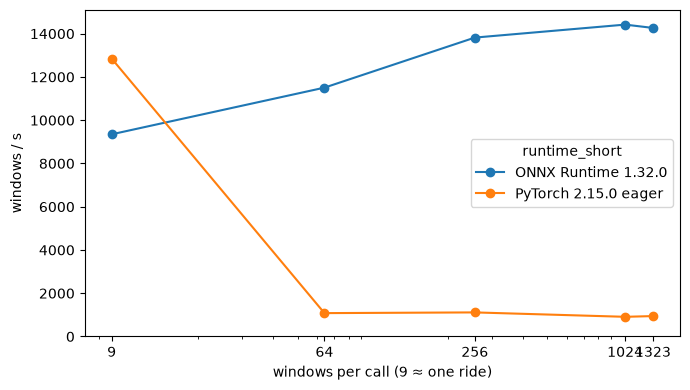

In [3]:
batch = results[results["metric"] == "batch_throughput"]
batch = batch.pivot_table(index="concurrency", columns="runtime_short", values="value", aggfunc="median")
ax = batch.plot(marker="o", logx=True, figsize=(7, 4))
ax.set_xlabel("windows per call (9 ≈ one ride)")
ax.set_ylabel("windows / s")
ax.set_ylim(0)
ax.set_xticks(batch.index, [str(i) for i in batch.index])
plt.tight_layout()
batch.round(0)

## Cold start in a new process (median of 5)

metric,cold_import_time,cold_load_time,first_prediction
runtime_short,,,
ONNX Runtime 1.32.0,93.0,26.6,0.9
PyTorch 2.15.0 eager,1399.8,2.2,1.9


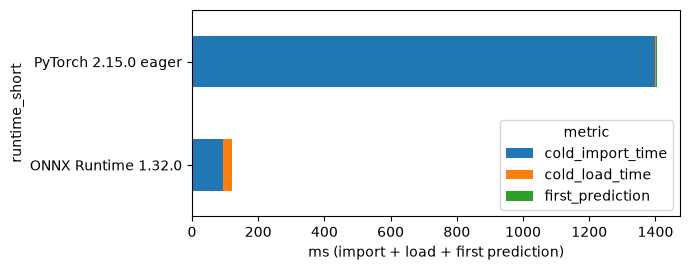

In [4]:
cold = results[results["metric"].isin(["cold_import_time", "cold_load_time", "first_prediction"])]
cold = cold.pivot_table(index="runtime_short", columns="metric", values="value", aggfunc="median")
cold = cold[["cold_import_time", "cold_load_time", "first_prediction"]]
ax = cold.plot(kind="barh", stacked=True, figsize=(7, 2.8))
ax.set_xlabel("ms (import + load + first prediction)")
plt.tight_layout()
cold.round(1)

## Hypothesis check

| Part of the hypothesis | Measured (median of 3 runs, min–max) | Verdict |
|---|---|---|
| Network for one ride ≈ 25 % faster | PyTorch 0.75 ms [0.72–0.82] · ONNX Runtime 0.89 ms [0.62–1.16]; per run: −17 %, +61 %, +9 % | **Not confirmed**: no stable gain, ONNX Runtime is much more variable |
| Whole ride ≈ 15 % faster (≤ 60 %) | PyTorch 1.51 ms [1.49–1.60] · ONNX Runtime 1.88 ms [1.22–2.47] | **Not confirmed** (same reason) |
| No gain for large batches | 1,323 windows: PyTorch 1,402 ms · ONNX Runtime **93 ms** → **15× faster** (from 64 windows up: 10–16×) | **Wrong, in the good direction** |
| Lower cold start and memory | import + load + first prediction: PyTorch **1,404 ms** · ONNX Runtime **120 ms** (12×); peak memory 558 → **303 MB** (−46 %) | **Confirmed** |
| Same macro F1 (0.272) | 0.272 and 0.272; same prediction on 150/150 rides | **Confirmed** |

## Interpretation

- **Large batches: 15× faster, because of the kernels, not the fusions.** The PyTorch 2.15 build for macOS / ARM has **no oneDNN** (`torch.backends.mkldnn.is_available()` is `False`), so its CPU convolution falls back to a slow path: per-window throughput *drops* from ≈ 12,800 windows/s (9 windows) to ≈ 900 windows/s (1,323 windows), and adding threads does not help ([diagnostics.txt](diagnostics.txt)). ONNX Runtime uses its own optimised CPU kernels (MLAS) and scales with threads (206 → 132 → 109 ms for 1 → 2 → 4 threads on 1,323 windows). Our hypothesis assumed both runtimes had equally good kernels and only differed by overhead: that was wrong for this build. On the Linux x86 cloud CPU, PyTorch also slowed down for large batches, but less (≈ 6,300 → 1,700 windows/s, see `benchmarks/vertex-t4/`).
- **One ride: no reliable gain.** At ≈ 9 windows both runtimes need under 1 ms, and the result depends mostly on thread scheduling: ONNX Runtime was 17 % faster in one run and 61 % slower in another (the Mac was shared with other Docker stacks). The fusions (BatchNorm folded, Conv + ReLU) save too little at this size to show through the noise. For the API, the network is only ≈ 0.8 ms of ≈ 4.5 ms per request anyway (Amdahl).
- **Start-up and memory: the clearest gain for serving.** Importing ONNX Runtime takes ≈ 0.09 s against ≈ 1.4 s for PyTorch, and the process uses ≈ 250 MB less memory. An API pod that serves the ONNX file does not need PyTorch at all (83 MB instead of 565 MB installed), so it would start faster and could run more replicas per node. MLflow and pandas are still imported by the API: the full pod start-up would drop by ≈ 1.3 s, not to 0.1 s.
- **Quality is unchanged**: same prediction on 150/150 rides, outputs differ by < 2e-6.
- **Decision**: keep the PyTorch pyfunc as the registered model, and propose ONNX Runtime for (a) **batch scoring** (15× on CPU, which removes most of the reason to use a GPU for it: 93 ms on the Mac CPU vs 17 ms on the T4) and (b) a **lighter API image** without PyTorch. Not done here: serving ONNX in the API would change the MLflow model (export at training time, `onnx` flavour) and needs the team's agreement.
- **Limits**: one machine (Mac M4, shared); 3 runs; the cold-start median uses 5 new processes; MLflow loading is excluded from both cold starts.